In [1]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm
import json

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
import pickle

from utils import *

from sklearn.metrics import confusion_matrix
import seaborn as sns

In [41]:
def matching(ref_library, spectra_data_ir, limits, lib_name, data_name, metric='pcc'):
    
    lim1, lim2 = limits

    wn_gl = np.array(spectra_data_ir.columns[:-5])

    idx_gl = list(np.logical_or(np.logical_and(wn_gl > lim1[0], wn_gl < lim1[1]),
                           np.logical_and(wn_gl > lim2[0], wn_gl < lim2[1])
                          ) ) + [False]*5


    wn_fl = np.array(ref_library.columns[:-5])

    idx_fl = list(np.logical_or(np.logical_and(wn_fl > lim1[0], wn_fl < lim1[1]),
                                np.logical_and(wn_fl > lim2[0], wn_fl < lim2[1])
                                )) + [False]*5
    
    #idx_fl[np.where(idx_fl)[0][-1]] = False

    x_train_ir = ref_library.iloc[:,idx_fl].to_numpy()
    x_train_ir = norm_spect_pivot(x_train_ir, norm_type='SNV')
    y_train_ir = ref_library.iloc[:,-2]


    x_test_ir = spectra_data_ir.loc[:,idx_gl].to_numpy()
    x_test_ir = norm_spect_pivot(x_test_ir, norm_type='SNV')
    
    if metric == 'pcc':
        pred_ = corr_matching(x_train_ir, y_train_ir, 
                              x_test_ir, r_min=0)
    else:
        pred_ = nn_matching(x_train_ir, y_train_ir, 
                              x_test_ir, r_min=0)
    pred_polymers = pred_[0]
    pred_hqi = pred_[1]
    pred_df = pd.DataFrame(pred_polymers)
    pred_df = pred_df.reset_index(drop=True) 
    polymer_name = 'polymer_'+lib_name
    hqi_name = 'hqi_'+lib_name
    pred_df.columns = [polymer_name]
    pred_df['id'] = spectra_data_ir['id']
    pred_df['background_'+data_name] = spectra_data_ir['background']
    pred_df[hqi_name] = pred_hqi
    
    
    #matches_mean = pred_df.reset_index().query('@hqi_name>.7').query('background!="background"').groupby(polymer_name).count()[hqi_name]

    #spectra_data_ir['polymer_flopp'] = pred_df['polymer_flopp']
    #spectra_data_ir['hqi_flopp'] = pred_df['hqi_flopp']

    return pred_df, pred_

In [42]:
flopp_df_trans = pd.read_csv('gloves_contamination/flopp_data_ir_final_transmission.csv')
del flopp_df_trans['Unnamed: 0']

flopp_df = pd.read_csv('gloves_contamination/flopp_data_ir_final.csv')
del flopp_df['Unnamed: 0']
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.query('polymer != "Cotton"').reset_index(drop=True)

rebecca_df = pd.read_csv('gloves_contamination/rebecca_data_ir_final.csv')
del rebecca_df['Unnamed: 0']
rebecca_df.columns = list(np.float64(rebecca_df.columns[:-4])) + list(rebecca_df.columns[-4:])

mIRageLibraySpectra_Removed = pd.read_csv('gloves_contamination/mIRageLibraySpectra_Removed.csv')
mIRageLibraySpectra_Removed.iloc[-1,2] = 'PE_15'
rebecca_df = rebecca_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "PTIR"')['ID']) for x in rebecca_df['id']])[0],
                             axis=0).reset_index(drop=True)

rebecca_df = rebecca_df.query('polymer == "PE"').reset_index(drop=True)

stearates_df = pd.read_csv('gloves_contamination/stearates_data_ir_final.csv')
del stearates_df['Unnamed: 0']
del stearates_df['background']

stearates_df.columns = list(np.float64(stearates_df.columns[:-4])) + list(stearates_df.columns[-4:])

pilot_phase_data_ir = pd.read_csv('gloves_contamination/pilot_phase_data_ir_final.csv')
del pilot_phase_data_ir['Unnamed: 0']
pilot_phase_data_ir.columns = list(np.float64(pilot_phase_data_ir.columns[:-5])) + list(pilot_phase_data_ir.columns[-5:])
pilot_phase_data_ir_excluded = pilot_phase_data_ir.query('background == "background"').reset_index(drop=True)
pilot_phase_data_ir = pilot_phase_data_ir.query('background == "no_background"').reset_index(drop=True)
pilot_phase_data_ir

ids_flopp = np.unique(flopp_df_trans.query('data_source == "flopp"')['id'])
ids_flopp_e = np.unique(flopp_df_trans.query('data_source == "flopp_e"')['id'])
ids_rebecca = np.unique(rebecca_df['id'])
ids_stearates = np.unique(stearates_df['id'])

pilot_phase_data_ir_res = pilot_phase_data_ir.copy()
del pilot_phase_data_ir['school']

In [43]:
pilot_phase_data_ir

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,id,background
0,2.231267,2.042529,1.889595,1.713540,1.571221,1.444183,1.223322,1.196712,1.336451,1.373121,...,-0.627869,-0.641498,-0.624750,-0.706928,-0.803992,-0.782889,786.299988,1411.699951,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_3,no_background
1,2.732352,1.827743,0.141659,-0.333680,-0.677244,-0.065838,1.082770,0.991519,0.039321,-0.767487,...,2.793962,1.448943,4.848981,7.446134,5.934084,4.146609,825.750000,1441.050049,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_4,no_background
2,0.123536,0.051271,-0.220288,-0.049846,0.278578,0.334729,0.332325,0.362714,0.254459,0.212723,...,-1.561059,-1.641840,-1.696559,-1.589906,-1.739175,-2.146179,798.650024,1462.000000,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_5,no_background
3,-0.955325,-0.641635,-0.017089,-0.133668,-0.073903,0.535185,1.007176,1.039265,1.012317,1.244014,...,-0.132718,-0.158415,-0.386613,-1.191183,-0.792877,0.112034,808.400024,1464.300049,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_6,no_background
4,0.845026,0.887625,0.928813,0.949297,0.928652,0.890891,0.873279,0.849208,0.843427,0.862283,...,-1.470464,-1.689345,-1.899279,-1.925507,-1.878205,-1.875397,811.000000,1444.550049,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_8,no_background
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1133,-1.429642,-1.410776,-1.382196,-1.345210,-1.299392,-1.248799,-1.198597,-1.138556,-1.080665,-1.030259,...,0.514042,0.533426,0.530843,0.475545,0.410778,0.358509,-2420.199951,2434.149902,MEC_02_072_ICB_AlSI_1_054261023_05252023_Run3_113,no_background
1134,2.158009,2.138077,2.121820,2.114246,2.118107,2.101187,2.072198,2.060888,2.044450,2.017727,...,-0.589313,-0.615697,-0.633129,-0.645694,-0.634030,-0.602631,-2365.600098,2408.699951,MEC_02_072_ICB_AlSI_1_054261023_05252023_Run3_114,no_background
1135,0.304476,0.319314,0.332314,0.363514,0.403028,0.428176,0.451243,0.481138,0.508436,0.540319,...,-0.565947,-0.576995,-0.610048,-0.639607,-0.627325,-0.627989,-2365.750000,2475.199951,MEC_02_072_ICB_AlSI_1_054261023_05252023_Run3_115,no_background
1136,2.374992,2.334719,2.304032,2.339319,2.410461,2.456345,2.512680,2.584526,2.620461,2.637685,...,-0.657874,-0.716493,-0.790519,-0.812454,-0.678506,-0.675699,-2363.149902,2477.100098,MEC_02_072_ICB_AlSI_1_054261023_05252023_Run3_116,no_background


In [44]:
data_match_new

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,id,background
0,-0.382818,-0.373358,-0.363377,-0.348227,-0.336989,-0.327300,-0.311538,-0.297327,-0.284209,-0.269309,...,-0.283147,-0.323126,-0.369811,-0.423077,-0.474506,-0.523723,NaN,NaN,PE38,no_background
1,-0.654062,-0.654062,-0.654062,-0.654062,-0.654062,-0.654062,-0.654062,-0.654062,-0.654062,-0.654062,...,-0.534795,-0.644802,-0.749832,-0.882509,-0.983991,-1.030035,NaN,NaN,iN10 stearate,no_background


In [81]:
data_match_new_PE38 = pd.read_csv('gloves_contamination/data_match_new_PE38.csv')

del data_match_new_PE38['Unnamed: 0']
data_match_new_PE38.columns = list(np.float64(data_match_new_PE38.columns[:-4])) + list(data_match_new_PE38.columns[-4:])
#data_match_new['school'] = 'A'
data_match_new_PE38

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,id,background
0,-0.382818,-0.373358,-0.363377,-0.348227,-0.336989,-0.3273,-0.311538,-0.297327,-0.284209,-0.269309,...,-0.283147,-0.323126,-0.369811,-0.423077,-0.474506,-0.523723,NaN,NaN,PE38,no_background


In [82]:
data_match_new_stearate = pd.read_csv('gloves_contamination/data_match_new_stearate.csv')

del data_match_new_stearate['Unnamed: 0']
data_match_new_stearate.columns = list(np.float64(data_match_new_stearate.columns[:-4])) + list(data_match_new_stearate.columns[-4:])
#data_match_new['school'] = 'A'
data_match_new_stearate


,1351.0,1353.0,1355.0,1357.0,1359.0,1361.0,1363.0,1365.0,1367.0,1369.0,...,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,id,background
0,-0.057222,-0.084622,-0.14339,-0.156188,-0.07246,0.037957,0.043309,0.007525,0.019686,0.052442,...,-0.807672,-0.90873,-1.005215,-1.127099,-1.220325,-1.262623,NaN,NaN,iN10 stearate,no_background


In [94]:
#pred_flopp_df = matching(flopp_df, 
#                         pilot_phase_data_ir, 
#                         limits=((980,1800),(2720, 2970)), 
#                         lib_name='ref', 
#                         data_name='final')

pred_rebecca_df_PE38 = matching(rebecca_df, 
                           data_match_new_PE38, 
                           limits=((980,1800),(2720, 2980)), 
                           lib_name='ref', data_name='final')

pred_stearates_df_PE38 = matching(stearates_df, 
                             data_match_new_PE38, 
                             limits=((980,1800),(2720, 2980)), 
                             lib_name='ref', data_name='final')

rebecca_stearates_df = pd.concat([rebecca_df,stearates_df], axis=0).reset_index(drop=True)

pred_rebecca_stearates_df_PE38 = matching(rebecca_stearates_df, 
                         data_match_new_PE38, 
                         limits=((980,1800),(2980, 2980)), lib_name='ref', data_name='final')


In [102]:
pd.concat([
    pred_rebecca_df_PE38[0].drop('background_final', axis=1),
    pred_rebecca_df_stearate[0].drop('background_final', axis=1)])

,polymer_ref,id,hqi_ref
0,PE,PE38,0.949293
0,PE,iN10 stearate,0.316007


In [115]:
pred_stearates_df_PE38[0].drop('background_final', axis=1)

,polymer_ref,id,hqi_ref
0,Calcium Stearate,PE38,0.915998


In [103]:
pd.concat([
    pred_rebecca_stearates_df_PE38[0].drop('background_final', axis=1),
    pred_rebecca_stearates_df_stearate[0].drop('background_final', axis=1)
])

,polymer_ref,id,hqi_ref
0,PE,PE38,0.777881
0,Zinc Stearate,iN10 stearate,0.852387


In [113]:
pred_rebecca_df_stearate = matching(rebecca_df, 
                           data_match_new_stearate, 
                           limits=((1351.0,1800),(2720, 2980)), 
                           lib_name='ref', data_name='final')

pred_stearates_df_stearate = matching(stearates_df, 
                             data_match_new_stearate, 
                             limits=((1351.0,1800),(2720, 2980)), 
                             lib_name='ref', data_name='final')

rebecca_stearates_df = pd.concat([rebecca_df,stearates_df], axis=0).reset_index(drop=True)

pred_rebecca_stearates_df_stearate = matching(rebecca_stearates_df, 
                         data_match_new_stearate, 
                         limits=((1351.0,1800),(2980, 2980)), lib_name='ref', data_name='final')


In [99]:
pred_rebecca_df_stearate[0].drop('background_final', axis=1)

,polymer_ref,id,hqi_ref
0,PE,iN10 stearate,0.316007


In [114]:
pred_stearates_df_stearate[0].drop('background_final', axis=1)

,polymer_ref,id,hqi_ref
0,Calcium Stearate,iN10 stearate,0.819902


In [101]:
pred_rebecca_stearates_df_stearate[0].drop('background_final', axis=1)

,polymer_ref,id,hqi_ref
0,Zinc Stearate,iN10 stearate,0.852387


In [118]:
matching(rebecca_df, 
                           data_match_new_stearate, 
                           limits=((1351.0,1800),(2980, 2980)), 
                           lib_name='ref', data_name='final')[0]

,polymer_ref,id,background_final,hqi_ref
0,PE,iN10 stearate,no_background,0.311247


In [117]:
matching(stearates_df, 
                             data_match_new_PE38, 
                             limits=((980,1800),(2980, 2980)), 
                             lib_name='ref', data_name='final')[0]

,polymer_ref,id,background_final,hqi_ref
0,Magnesium Stearate v2,PE38,no_background,0.538773


In [51]:
flopp_stearates_df = pd.concat([flopp_df,stearates_df], axis=0).reset_index(drop=True)
pred_flopp_stearates_df = matching(flopp_stearates_df, 
                         data_match_new, 
                         limits=((980,1800),(2720, 2970)), lib_name='ref', data_name='final')

rebecca_stearates_df = pd.concat([rebecca_df,stearates_df], axis=0).reset_index(drop=True)
pred_rebecca_stearates_df = matching(rebecca_stearates_df, 
                         data_match_new, 
                         limits=((980,1800),(2720, 2980)), lib_name='ref', data_name='final')


In [52]:
pred_rebecca_df[0].query('hqi_ref>=.7').groupby('polymer_ref').count().iloc[:,:1]

,id
polymer_ref,
PE,1


In [53]:
pred_stearates_df[0].query('hqi_ref>=.7').groupby('polymer_ref').count().iloc[:,:1]

,id
polymer_ref,
Calcium Stearate,2


In [54]:
pred_rebecca_stearates_df[0].query('hqi_ref>=.7').groupby('polymer_ref').count().iloc[:,:1]

,id
polymer_ref,
Calcium Stearate,1
PE,1


In [55]:
idx_matches_stearates = np.array(pred_stearates_df[0].query('hqi_ref>=.7')['id'])

pred_rebecca_ch_df = matching(rebecca_df, data_match_new, limits=((980,980),(2720, 2980)), lib_name='ref', data_name='final')
pred_stearates_ch_df = matching(stearates_df, data_match_new, limits=((980,980),(2720, 2980)), lib_name='ref', data_name='final')

pred_rebecca_fp_df = matching(rebecca_df, data_match_new, limits=((980,1800),(2720, 2720)), lib_name='ref', data_name='final')
pred_stearates_fp_df = matching(stearates_df, data_match_new, limits=((980,1800),(2720, 2720)), lib_name='ref', data_name='final')


In [60]:
pred_rebecca_ch_df[0].query('hqi_ref>=.7').groupby('polymer_ref').count().iloc[:,:1]

,id
polymer_ref,
PE,2


In [61]:
pred_rebecca_fp_df[0].query('hqi_ref>=.7').groupby('polymer_ref').count().iloc[:,:1]

,id
polymer_ref,
PE,1


In [63]:
pred_stearates_ch_df[0].query('hqi_ref>=.7').groupby('polymer_ref').count().iloc[:,:1]

,id
polymer_ref,
Sodium Stearate,2


In [62]:
pred_stearates_fp_df[0].query('hqi_ref>=.7').groupby('polymer_ref').count().iloc[:,:1]

,id
polymer_ref,
Calcium Stearate,1


In [57]:
print('rebecca_ch:', 
      np.round(np.mean(pred_rebecca_ch_df[0].query('id in @idx_matches_stearates')['hqi_ref']), 2),
      np.round(np.std(pred_rebecca_ch_df[0].query('id in @idx_matches_stearates')['hqi_ref']), 2))

print('stearates_ch:', np.round(np.mean(pred_stearates_ch_df[0].query('id in @idx_matches_stearates')['hqi_ref']),2),
      np.round(np.std(pred_stearates_ch_df[0].query('id in @idx_matches_stearates')['hqi_ref']),2))

print('rebecca_fp:', np.round(np.mean(pred_rebecca_fp_df[0].query('id in @idx_matches_stearates')['hqi_ref']),2),
      np.round(np.std(pred_rebecca_fp_df[0].query('id in @idx_matches_stearates')['hqi_ref']),2))

print('stearates_fp:', np.round(np.mean(pred_stearates_fp_df[0].query('id in @idx_matches_stearates')['hqi_ref']), 2),
      np.round(np.std(pred_stearates_fp_df[0].query('id in @idx_matches_stearates')['hqi_ref']),2))

print('rebecca_full:', np.round(pred_rebecca_df[0].query('id in @idx_matches_stearates')['hqi_ref'].mean(), 2),
      np.round(pred_rebecca_df[0].query('id in @idx_matches_stearates')['hqi_ref'].std(), 2))

print('stearates_full:', np.round(pred_stearates_df[0].query('id in @idx_matches_stearates')['hqi_ref'].mean(), 2),
      np.round(pred_stearates_df[0].query('id in @idx_matches_stearates')['hqi_ref'].std(), 2))


rebecca_ch: 0.99 0.0
stearates_ch: 0.99 0.0
rebecca_fp: 0.56 0.21
stearates_fp: 0.71 0.17
rebecca_full: 0.66 0.41
stearates_full: 0.88 0.05


In [58]:
dh_fp_df = pd.DataFrame(
    np.array(
        [[
            np.round(np.mean(pred_rebecca_ch_df[0].query('id in @idx_matches_stearates')['hqi_ref']), 2),
            np.round(np.std(pred_rebecca_ch_df[0].query('id in @idx_matches_stearates')['hqi_ref']), 2)
        ],
         [
             np.round(np.mean(pred_stearates_ch_df[0].query('id in @idx_matches_stearates')['hqi_ref']),2),
             np.round(np.std(pred_stearates_ch_df[0].query('id in @idx_matches_stearates')['hqi_ref']),2)
         ],
         [
             np.round(np.mean(pred_rebecca_fp_df[0].query('id in @idx_matches_stearates')['hqi_ref']),2),
             np.round(np.std(pred_rebecca_fp_df[0].query('id in @idx_matches_stearates')['hqi_ref']),2)
         ],
         [
             np.round(np.mean(pred_stearates_fp_df[0].query('id in @idx_matches_stearates')['hqi_ref']), 2),
             np.round(np.std(pred_stearates_fp_df[0].query('id in @idx_matches_stearates')['hqi_ref']),2)
         ]
        ])
)
dh_fp_df.columns = ['mean', 'std']
dh_fp_df['match'] = ['rebecca_ch', 'stearates_ch', 'rebecca_fp', 'stearates_fp']
dh_fp_df

,mean,std,match
0,0.99,0.00,rebecca_ch
1,0.99,0.00,stearates_ch
2,0.56,0.21,rebecca_fp
3,0.71,0.17,stearates_fp


In [107]:
#diff_table['diff (stearate - poly)'] = (diff_table['hqi_ref_y'] - diff_table['hqi_ref_x'])
#diff_table.loc[:, ['polymer_ref_x', 'id', 'polymer_ref_y', 'diff (stearate - poly)']]#.to_csv('gloves_contamination/results/distribution_differences.csv')


In [109]:
pilot_phase_data_ir_res['polymer_rebecca'] = pred_rebecca_df[0]['polymer_ref']
pilot_phase_data_ir_res['hqi_rebecca'] = pred_rebecca_df[0]['hqi_ref']
pilot_phase_data_ir_res['id_top_match_rebecca'] = np.array(rebecca_df.iloc[np.array(pred_rebecca_df[1][0].index),-1])
#pilot_phase_data_ir_res['data_source_rebecca'] = 'rebecca'

pilot_phase_data_ir_res['polymer_stearates_fp'] = pred_stearates_fp_df[0]['polymer_ref']
pilot_phase_data_ir_res['hqi_stearates_fp'] = pred_stearates_fp_df[0]['hqi_ref']
pilot_phase_data_ir_res['id_top_match_stearates_fp'] = np.array(stearates_df.iloc[np.array(pred_stearates_fp_df[1][0].index),-1])
#pilot_phase_data_ir_res['data_source_stearates'] = 'stearates'

pilot_phase_data_ir_res['polymer_rebecca_fp'] = pred_rebecca_fp_df[0]['polymer_ref']
pilot_phase_data_ir_res['hqi_rebecca_fp'] = pred_rebecca_fp_df[0]['hqi_ref']
pilot_phase_data_ir_res['id_top_match_rebecca_fp'] = np.array(rebecca_df.iloc[np.array(pred_rebecca_fp_df[1][0].index),-1])
#pilot_phase_data_ir_res['data_source_rebecca_fp'] = np.array(rebecca_df.iloc[np.array(pred_rebecca_df[1][0].index),-1])
pilot_phase_data_ir_res.query('hqi_rebecca>.7').to_csv('gloves_contamination/pilot_phase_data_ir_res.csv')
#pilot_phase_data_ir_res.query('hqi_rebecca>.7').to_csv('gloves_contamination/pilot_phase_data_ir_res_full.csv')


In [118]:
pilot_phase_data_ir_res = pd.read_csv('gloves_contamination/pilot_phase_data_ir_res.csv')
pilot_phase_data_ir_res_full = pd.read_csv('gloves_contamination/pilot_phase_data_ir_res_full.csv')
del pilot_phase_data_ir_res_full['Unnamed: 0']

In [120]:
additional_ids = [x for x in pilot_phase_data_ir_res_full['id'] if x not in list(pilot_phase_data_ir_res['id'])]
pilot_phase_data_ir_res_full.query('id in @additional_ids').to_csv('gloves_contamination/pilot_phase_data_ir_res_new_data.csv')


In [39]:
#idx_match = pred_rebecca_stearates_df[0]['hqi_ref'] > .7#[True] * pred_flopp_df[0].shape[0]
#idx_match = np.logical_and(pred_rebecca_df[0]['hqi_ref'] > .7, 
#                           pred_stearates_df[0]['hqi_ref'] > .7)
idx_match = pred_rebecca_df[0]['hqi_ref']>=.7#[True] * pred_flopp_df[0].shape[0]

#labels_rebecca_stearates = np.unique(np.array(pred_rebecca_stearates_df[0]['polymer_ref']))
labels_rebecca_stearates = np.concatenate([np.array(list(set(pred_rebecca_df[0]['polymer_ref']))),
                                           np.array(list(set(pred_stearates_df[0]['polymer_ref'])))])

labels_rebecca_stearates = np.array(pd.DataFrame({'label':labels_rebecca_stearates,
 'a':[1*('Stearate' in x) for x in labels_rebecca_stearates]}).sort_values(['a', 'label'])['label'])

#labels_flopp = np.unique(np.array(pred_flopp_df[0]['polymer_ref']))
mat = confusion_matrix(np.array(pred_rebecca_df[0]['polymer_ref'].loc[idx_match]), 
                       np.array(pred_rebecca_stearates_df[0]['polymer_ref'].loc[idx_match]),
                       labels=labels_rebecca_stearates)

mat2 = mat[mat.sum(1)>0,:]
idx_pos_col = mat2.sum(0)>0
mat2 = mat2[:, idx_pos_col]
mat2_count = mat2.copy()
mat2 = (mat2 / mat2.sum(1)[:,None])
mat2 = np.round(mat2, 2)


mat2_df = pd.DataFrame(mat2)
mat2_df.columns = labels_rebecca_stearates[idx_pos_col]
mat2_df['index'] = labels_rebecca_stearates[mat.sum(1)>0]
mat2_df = mat2_df.set_index('index')
mat2_df.to_csv('gloves_contamination/results_pilot_phase/confusion_matrix_rebecca_stearates.csv')
mat2_df

,PE,Calcium Stearate,Magnesium Stearate v2,Zinc Stearate
index,,,,
PE,0.47,0.35,0.12,0.06


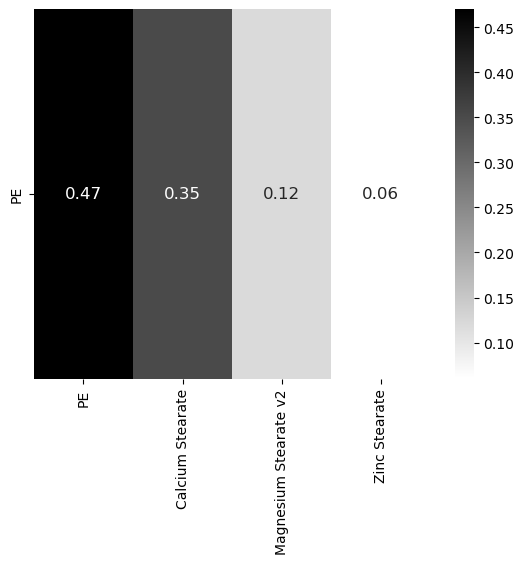

In [40]:
_ = sns.heatmap(mat2, 
                #annot=True,
                yticklabels=labels_rebecca_stearates[mat.sum(1)>0], 
                xticklabels=labels_rebecca_stearates[idx_pos_col],
                cmap = 'binary',
                annot=True,
                annot_kws={'fontsize':12})
_ = plt.savefig('gloves_contamination/results_pilot_phase/confusion_matrix_rebecca_stearates.png',bbox_inches='tight')

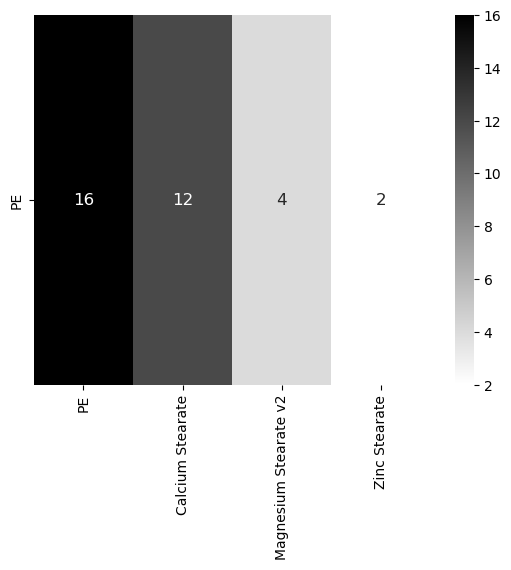

In [41]:
_ = sns.heatmap(mat2_count, 
                #annot=True,
                yticklabels=labels_rebecca_stearates[mat.sum(1)>0], 
                xticklabels=labels_rebecca_stearates[idx_pos_col],
                cmap = 'binary',
                annot=True,
                annot_kws={'fontsize':12},
                fmt=".0f")
_ = plt.savefig('gloves_contamination/results_pilot_phase/confusion_matrix_rebecca_stearates_count.png',bbox_inches='tight')

# Raman

In [179]:
def matching_r(ref_library, spectra_data_ir, limits, lib_name, data_name):
    
    lim1, lim2 = limits

    wn_gl = np.array(spectra_data_ir.columns[:-3])

    idx_gl = list(np.logical_and(wn_gl > lim1, wn_gl < lim2)) + [False]*3


    wn_fl = np.array(ref_library.columns[:-4])

    idx_fl = list(np.logical_and(wn_fl > lim1, wn_fl < lim2)) + [False]*4
    
    #idx_fl[np.where(idx_fl)[0][-1]] = False

    x_train_ir = ref_library.iloc[:,idx_fl].to_numpy()
    x_train_ir = norm_spect_pivot(x_train_ir, norm_type='SNV')
    y_train_ir = ref_library.iloc[:,-2]


    x_test_ir = spectra_data_ir.loc[:,idx_gl].to_numpy()
    x_test_ir = norm_spect_pivot(x_test_ir, norm_type='SNV')
    
    pred_ = corr_matching(x_train_ir, y_train_ir, 
                          x_test_ir, r_min=0)
    pred_polymers = pred_[0]
    pred_hqi = pred_[1]
    pred_df = pd.DataFrame(pred_polymers)
    pred_df = pred_df.reset_index(drop=True) 
    polymer_name = 'polymer_'+lib_name
    hqi_name = 'hqi_'+lib_name
    pred_df.columns = [polymer_name]
    pred_df['id'] = spectra_data_ir['id']
    #pred_df['background_'+data_name] = spectra_data_ir['background']
    pred_df[hqi_name] = pred_hqi
    
    
    #matches_mean = pred_df.reset_index().query('@hqi_name>.7').query('background!="background"').groupby(polymer_name).count()[hqi_name]

    #spectra_data_ir['polymer_flopp'] = pred_df['polymer_flopp']
    #spectra_data_ir['hqi_flopp'] = pred_df['hqi_flopp']

    return pred_df, pred_

In [180]:
slopp_slopp_e_pivot = pd.read_csv('processed_data/slopp_slopp_e_pivot.csv')
del slopp_slopp_e_pivot['Unnamed: 0']
slopp_slopp_e_pivot = slopp_slopp_e_pivot.rename({'file_name':'id'},axis=1) 

In [181]:
with open('gloves_contamination/pilot_phase_data_raman_saturation.json', 'r') as f:
    saturated_wn_dict = json.load(f)

#with open('gloves_contamination/gloves_data_raman_saturation_trunc.json', 'r') as f:
    #saturated_wn_dict_trunc = json.load(f)
    
ids_sat = list(saturated_wn_dict.keys())

#ids_sat_trunc = list(saturated_wn_dict_trunc.keys())
#ids_sat_diff = np.array(ids_sat)[[x not in ids_sat_trunc for x in ids_sat]]

slopp_df = pd.read_csv('gloves_contamination/slopp_data_raman_final_specy.csv')
del slopp_df['Unnamed: 0']
slopp_df.columns = list(np.float64(slopp_df.columns[:-4])) + list(slopp_df.columns[-4:])
#slopp_df = slopp_df.query('polymer != "Cotton"').reset_index(drop=True)
slopp_df = slopp_df.query('polymer != "Cotton" and polymer !="Dyed Cellulose"').reset_index(drop=True)

rebecca_df = pd.read_csv('gloves_contamination/rebecca_data_raman_final_specy.csv')
del rebecca_df['Unnamed: 0']
rebecca_df.columns = list(np.float64(rebecca_df.columns[:-4])) + list(rebecca_df.columns[-4:])

mIRageLibraySpectra_Removed = pd.read_csv('gloves_contamination/mIRageLibraySpectra_Removed.csv')
mIRageLibraySpectra_Removed.iloc[-1,2] = 'PE_15'
rebecca_df = rebecca_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "Raman"')['ID']) for x in rebecca_df['id']])[0],
                             axis=0).reset_index(drop=True)


stearates_df = pd.read_csv('gloves_contamination/stearates_data_raman_final_specy.csv')
del stearates_df['Unnamed: 0']
stearates_df.columns = list(np.float64(stearates_df.columns[:-4])) + list(stearates_df.columns[-4:])

pilot_phase_data_raman = pd.read_csv('gloves_contamination/pilot_phase_data_raman_final_specy.csv')
del pilot_phase_data_raman['Unnamed: 0']
pilot_phase_data_raman.columns = list(np.float64(pilot_phase_data_raman.columns[:-4])) + list(pilot_phase_data_raman.columns[-4:])
#pilot_phase_data_raman = pilot_phase_data_raman.query('id in @ids_sat').reset_index(drop=True)
pilot_phase_data_raman = pilot_phase_data_raman.query('id not in @ids_sat').reset_index(drop=True)
pilot_phase_data_raman
#gloves_data_raman = gloves_data_raman.query('background == "no_background"').reset_index(drop=True)

ids_slopp = np.unique(slopp_slopp_e_pivot.query('data_source == "slopp"')['id'])
ids_slopp_e = np.unique(slopp_slopp_e_pivot.query('data_source == "slopp_e"')['id'])
ids_rebecca = np.unique(rebecca_df['id'])
ids_stearates = np.unique(stearates_df['id'])

rebecca_df = rebecca_df.query('polymer == "PE"').reset_index(drop=True)

In [124]:
#gloves_data_raman_excluded.to_csv('gloves_contamination/results_raman/excluded_spectra.csv')

In [125]:
#_ = plt.plot(gloves_data_raman.query('id in @ids_sat_diff').iloc[:,:-3].T)

In [126]:
#_ = plt.plot(gloves_data_raman.iloc[:,:-3].T)

In [182]:
pilot_phase_data_raman_res = pilot_phase_data_raman.copy()
del pilot_phase_data_raman['school']

In [183]:
pilot_phase_data_raman.shape

(1462, 1576)

In [149]:
stearates_df.shape

(181, 1577)

(array([  7.,  23.,  31., 154., 348., 374., 174.,  70.,  34.,  30.]),
 array([-21.,  -9.,   3.,  15.,  27.,  39.,  51.,  63.,  75.,  87.,  99.]),
 <BarContainer object of 10 artists>)

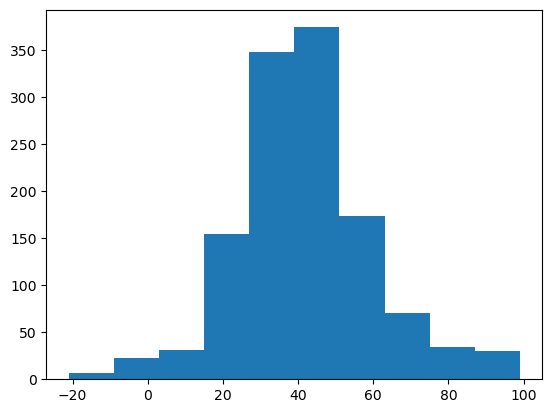

In [178]:
(ref_library, 
 spectra_data_ir, 
 limits, 
 lib_name, 
 data_name) = (
    stearates_df, 
    pilot_phase_data_raman,#.query('id in @ids_matches'), 
    (355,3500), 
    'ref', 
    'final')
    
lim1, lim2 = limits

wn_gl = np.array(spectra_data_ir.columns[:-3])

idx_gl = list(np.logical_and(wn_gl > lim1, wn_gl < lim2)) + [False]*3


wn_fl = np.array(ref_library.columns[:-4])

idx_fl = list(np.logical_and(wn_fl > lim1, wn_fl < lim2)) + [False]*4
    
    #idx_fl[np.where(idx_fl)[0][-1]] = False

x_train_ir = ref_library.iloc[:,idx_fl].to_numpy()
x_train_ir = norm_spect_pivot(x_train_ir, norm_type='SNV')
y_train_ir = ref_library.iloc[:,-2]


x_test_ir = spectra_data_ir.loc[:,idx_gl].to_numpy()
x_test_ir = norm_spect_pivot(x_test_ir, norm_type='SNV')

plt.hist(np.round(np.corrcoef(
     x_test_ir,
     x_train_ir)[:1462,1462:]*100).max(1))

In [184]:
pred_slopp_df = matching_r(slopp_df, pilot_phase_data_raman, limits=(355,3500), lib_name='ref', data_name='final')
pred_rebecca_df = matching_r(rebecca_df, pilot_phase_data_raman, limits=(355,3500), lib_name='ref', data_name='final')
pred_stearates_df = matching_r(stearates_df, pilot_phase_data_raman, limits=(355,3500), lib_name='ref', data_name='final')


In [185]:
#ids_matches = list(pred_rebecca_df[0].query('hqi_ref > .7')['id'])

In [115]:
#pred_slopp_df[0].query('id in @ids_sat_diff')

In [186]:
slopp_stearates_df = pd.concat([slopp_df,stearates_df], axis=0).reset_index(drop=True)
pred_slopp_stearates_df = matching_r(slopp_stearates_df, pilot_phase_data_raman, limits=(355,3500), lib_name='ref', data_name='final')

rebecca_stearates_df = pd.concat([rebecca_df,stearates_df], axis=0).reset_index(drop=True)
pred_rebecca_stearates_df = matching_r(rebecca_stearates_df, pilot_phase_data_raman, limits=(355,3500), lib_name='ref', data_name='final')


In [63]:
#gloves_data_raman_res = gloves_data_raman.copy()

In [188]:
pred_stearates_df[0].query('hqi_ref>=.7').groupby('polymer_ref').count().iloc[:,:1]

,id
polymer_ref,
Calcium Stearate,48
Magnesium Stearate v2,2
Sodium Stearate,12
Zinc Stearate,12


In [189]:
pred_rebecca_df[0].query('hqi_ref>=.7').groupby('polymer_ref').count().iloc[:,:1]

,id
polymer_ref,
PE,95


In [190]:
pred_rebecca_stearates_df[0].query('hqi_ref>=.7').groupby('polymer_ref').count().iloc[:,:1]

,id
polymer_ref,
Calcium Stearate,9
Magnesium Stearate v2,1
PE,84
Zinc Stearate,1


0.023343202946948832


(array([  1.,   0.,   0.,   1.,   1.,   1., 103., 280., 185.,  40.]),
 array([-0.11978179, -0.10131069, -0.08283958, -0.06436848, -0.04589737,
        -0.02742627, -0.00895516,  0.00951594,  0.02798704,  0.04645815,
         0.06492925]),
 <BarContainer object of 10 artists>)

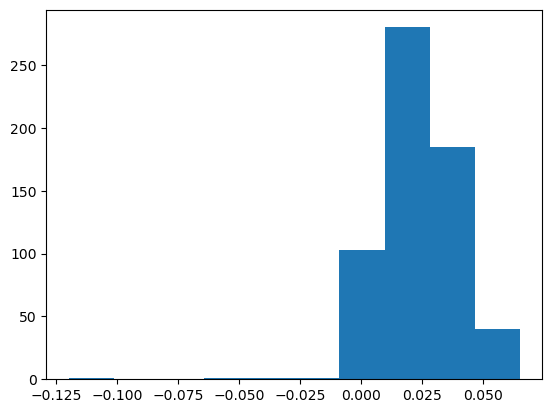

In [304]:
diff_table = pred_rebecca_df[0].merge(pred_stearates_df[0], on='id').query('hqi_ref_x>=.7 and hqi_ref_y>=.7 ')
print(np.mean(diff_table['hqi_ref_y'] - diff_table['hqi_ref_x']))
plt.hist(diff_table['hqi_ref_y'] - diff_table['hqi_ref_x'])

In [305]:
diff_table['diff (stearate - poly)'] = (diff_table['hqi_ref_y'] - diff_table['hqi_ref_x'])
diff_table.loc[:, ['polymer_ref_x', 'id', 'polymer_ref_y', 'diff (stearate - poly)']].to_csv('gloves_contamination/results_raman/distribution_differences.csv')

In [192]:
pilot_phase_data_raman_res['polymer_rebecca'] = pred_rebecca_df[0]['polymer_ref']
pilot_phase_data_raman_res['hqi_rebecca'] = pred_rebecca_df[0]['hqi_ref']
pilot_phase_data_raman_res['id_top_match_rebecca'] = np.array(rebecca_df.iloc[np.array(pred_rebecca_df[1][0].index),-1])

#pilot_phase_data_raman_res['polymer_stearates'] = pred_stearates_df[0]['polymer_ref']
#pilot_phase_data_raman_res['hqi_stearates'] = pred_stearates_df[0]['hqi_ref']
#pilot_phase_data_raman_res['id_top_match_stearates'] = np.array(stearates_df.iloc[np.array(pred_stearates_df[1][0].index),-1])

#gloves_data_raman_res['data_source_rebecca'] = 'rebecca'
pilot_phase_data_raman_res.query('hqi_rebecca>.7').to_csv('gloves_contamination/pilot_phase_data_raman_res.csv')


,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3495.0,3497.0,3499.0,map_x,map_y,id,school,polymer_rebecca,hqi_rebecca,id_top_match_rebecca
4,-0.340492,-0.352334,-0.306848,-0.255907,-0.289309,-0.323057,-0.357466,-0.354209,-0.326792,-0.331842,...,-0.513759,-0.513759,-0.513759,862.299988,1482.300049,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_9,IAO,PE,0.974409,PE_10
7,-0.531420,-0.531420,-0.531420,-0.531420,-0.531420,-0.531420,-0.531420,-0.531420,-0.531420,-0.531420,...,-0.531420,-0.474118,-0.385328,814.099976,1492.050049,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_12,IAO,PE,0.928456,PE_10
8,-0.277306,-0.336811,-0.348638,-0.348592,-0.335259,-0.333589,-0.354056,-0.365401,-0.370895,-0.383777,...,-0.725174,-0.725174,-0.725174,817.000000,1492.500000,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_13,IAO,PE,0.901931,PE_10
9,-0.556417,-0.673642,-0.606882,-0.516284,-0.624353,-0.695136,-0.695136,-0.695136,-0.695136,-0.695136,...,-0.695136,-0.695136,-0.695136,811.500000,1497.650024,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_14,IAO,PE,0.904238,PE_10
11,-0.516533,-0.434363,-0.338199,-0.258553,-0.402470,-0.558385,-0.737076,-0.665179,-0.432544,-0.408454,...,-0.806905,-0.806905,-0.806905,779.000000,1499.000000,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2_16,IAO,PE,0.748657,PE_10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1379,-0.699487,-0.699487,-0.699487,-0.687681,-0.541639,-0.496373,-0.642416,-0.699487,-0.699487,-0.699487,...,-0.699487,-0.699487,-0.699487,-180.550003,-642.000000,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_115,IAO,PE,0.901968,PE_7
1380,-0.278008,-0.372375,-0.497052,-0.617906,-0.617906,-0.617906,-0.617906,-0.617906,-0.617906,-0.617906,...,-0.617906,-0.617906,-0.617906,-195.050003,-641.500000,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_116,IAO,PE,0.930620,PE_7
1381,-0.220512,-0.238062,-0.308327,-0.383792,-0.383792,-0.383792,-0.383792,-0.383792,-0.383792,-0.383792,...,-0.383792,-0.383792,-0.383792,-172.350006,-638.400024,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_117,IAO,PE,0.984284,PE_4
1382,-0.756751,-0.756751,-0.554271,-0.325309,-0.312150,-0.393617,-0.654717,-0.579799,-0.289343,-0.354823,...,-0.457049,-0.520136,-0.737126,-163.500000,-631.200012,MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1_118,IAO,PE,0.849807,PE_7


In [210]:
pilot_phase_data_raman_res = pd.read_csv('gloves_contamination/pilot_phase_data_raman_res.csv')
pilot_phase_data_raman_res_full = pd.read_csv('gloves_contamination/pilot_phase_data_raman_res_full.csv')
del pilot_phase_data_raman_res_full['Unnamed: 0']

In [213]:
additional_ids_raman = [x for x in pilot_phase_data_raman_res_full['id'] if x not in list(pilot_phase_data_raman_res['id'])]

pilot_phase_data_raman_res_full.query('id in @additional_ids_raman').to_csv('gloves_contamination/pilot_phase_data_raman_res_new_data.csv')


In [124]:
gloves_data_raman_res['polymer_slopp'] = pred_slopp_df[0]['polymer_ref']
gloves_data_raman_res['hqi_slopp'] = pred_slopp_df[0]['hqi_ref']
gloves_data_raman_res['id_top_match_slopp'] = np.array(slopp_df.iloc[np.array(pred_slopp_df[1][0].index),-1])
gloves_data_raman_res['data_source_slopp'] = ['slopp' if x in ids_flopp else 'slopp_e' for x in gloves_data_raman_res['id_top_match_slopp']]

gloves_data_raman_res['polymer_stearates'] = pred_stearates_df[0]['polymer_ref']
gloves_data_raman_res['hqi_stearates'] = pred_stearates_df[0]['hqi_ref']
gloves_data_raman_res['id_top_match_stearates'] = np.array(stearates_df.iloc[np.array(pred_stearates_df[1][0].index),-1])
gloves_data_raman_res['data_source_stearates'] = 'stearates'

gloves_data_raman_res['polymer_rebecca'] = pred_rebecca_df[0]['polymer_ref']
gloves_data_raman_res['hqi_rebecca'] = pred_rebecca_df[0]['hqi_ref']
gloves_data_raman_res['id_top_match_rebecca'] = np.array(rebecca_df.iloc[np.array(pred_rebecca_df[1][0].index),-1])
gloves_data_raman_res['data_source_rebecca'] = 'rebecca'

gloves_data_raman_res['polymer_slopp_stearates'] = pred_slopp_stearates_df[0]['polymer_ref']
gloves_data_raman_res['hqi_slopp_stearates'] = pred_slopp_stearates_df[0]['hqi_ref']
gloves_data_raman_res['id_top_match_slopp_stearates'] = np.array(slopp_stearates_df.iloc[np.array(pred_slopp_stearates_df[1][0].index),-1])
gloves_data_raman_res['data_source_slopp_stearates'] = ['slopp' if x in ids_slopp else 'slopp_e' if x in ids_slopp_e else 'stearates' for x in gloves_data_raman_res['id_top_match_slopp_stearates']]

gloves_data_raman_res['polymer_rebecca_stearates'] = pred_rebecca_stearates_df[0]['polymer_ref']
gloves_data_raman_res['hqi_rebecca_stearates'] = pred_rebecca_stearates_df[0]['hqi_ref']
gloves_data_raman_res['id_top_match_rebecca_stearates'] = np.array(rebecca_stearates_df.iloc[np.array(pred_rebecca_stearates_df[1][0].index),-1])
gloves_data_raman_res['data_source_rebecca_stearates'] = ['rebecca' if x in ids_rebecca else 'stearates' for x in gloves_data_raman_res['id_top_match_rebecca_stearates']]

gloves_data_raman_res


,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,id_top_match_rebecca,data_source_rebecca,polymer_slopp_stearates,hqi_slopp_stearates,id_top_match_slopp_stearates,data_source_slopp_stearates,polymer_rebecca_stearates,hqi_rebecca_stearates,id_top_match_rebecca_stearates,data_source_rebecca_stearates
0,0.068679,0.074065,0.071034,0.065058,0.047093,0.033149,0.026839,0.011299,-0.010163,0.012040,...,PP_35,rebecca,Sodium Stearate,0.404022,Sodium Stearate_15,stearates,Sodium Stearate,0.404022,Sodium Stearate_15,stearates
1,0.639523,0.605787,0.593576,0.588226,0.605935,0.638924,0.700918,0.677862,0.600250,0.548362,...,PSL_52,rebecca,Calcium Stearate,0.468796,Calcium Stearate_102,stearates,Calcium Stearate,0.468796,Calcium Stearate_102,stearates
2,2.712312,2.882443,2.986626,3.064666,3.013808,2.937730,2.813776,2.706437,2.609756,2.684483,...,PSL_52,rebecca,Calcium Stearate,0.502736,Calcium Stearate_102,stearates,Calcium Stearate,0.502736,Calcium Stearate_102,stearates
3,0.132527,0.125327,0.127415,0.130922,0.126859,0.119735,0.106798,0.104577,0.109229,0.105809,...,PP_35,rebecca,Sodium Stearate,0.425920,Sodium Stearate_15,stearates,Sodium Stearate,0.425920,Sodium Stearate_15,stearates
4,1.606523,1.639777,1.717443,1.794196,1.747182,1.683180,1.586928,1.492610,1.399531,1.431163,...,PSL_52,rebecca,Calcium Stearate,0.546601,Calcium Stearate_102,stearates,Calcium Stearate,0.546601,Calcium Stearate_102,stearates
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1234,0.114177,0.105439,0.110182,0.117332,0.117448,0.113142,0.100444,0.103548,0.116788,0.104578,...,PE_9,rebecca,Sodium Stearate,0.980794,Sodium Stearate_89,stearates,Sodium Stearate,0.980794,Sodium Stearate_89,stearates
1235,0.437370,0.444869,0.446204,0.443742,0.413838,0.398329,0.410147,0.409680,0.401332,0.377332,...,PE_7,rebecca,Calcium Stearate,0.959347,Calcium Stearate_102,stearates,Calcium Stearate,0.959347,Calcium Stearate_102,stearates
1236,0.848493,0.941898,0.958407,0.953525,0.901739,0.860630,0.839792,0.838897,0.850794,0.812097,...,PE_7,rebecca,Calcium Stearate,0.742729,Calcium Stearate_102,stearates,Calcium Stearate,0.742729,Calcium Stearate_102,stearates
1237,-0.041655,-0.056600,-0.058043,-0.056168,-0.051042,-0.052543,-0.066624,-0.070305,-0.067314,-0.065294,...,PE_25,rebecca,Zinc Stearate,0.995632,Zinc Stearate_63,stearates,Zinc Stearate,0.995632,Zinc Stearate_63,stearates


In [125]:
#df_matches = gloves_data_ir_res.query('hqi_stearates > .7').loc[:,['map_x', 'map_y', 'id', 'hqi_stearates']].reset_index(drop=True)
df_matches = gloves_data_raman_res.loc[:,['map_x', 'map_y', 'id', 'hqi_stearates']].reset_index(drop=True)
df_matches_info = np.array([x.split('_')[:3] for x in df_matches.loc[:,'id']])
df_matches['id_file'] = [x[0]+'_'+x[1]+'_'+x[2] for x in df_matches_info]
id_file_list = np.unique(df_matches['id_file'])

df_particles = pd.read_csv('gloves_contamination/particle_info_all.csv')
del df_particles['Unnamed: 0']

df_list = []
for id_file in id_file_list:
    #if id_file in ['Blank_-_01', 'Blank_-_02']:
    #    continue
    print(id_file)
    #df_matches_file = df_matches.query('hqi_stearates > .7').query('id_file in @id_file').reset_index(drop=True)
    df_matches_file = df_matches.query('id_file in @id_file').reset_index(drop=True)
    df_particles_file = df_particles.query('id_file in @id_file').reset_index(drop=True)
    coords_matches = df_matches_file.loc[:,['map_x', 'map_y']]
    coords_particles = df_particles_file.loc[:,['map_x', 'map_y']]

    #id_matches = np.argmin(pairwise_distances(coords_matches,
    #                   coords_particles), axis=1)
    
    table_match_coords = pd.DataFrame({
    'idx_part':np.arange(coords_particles.shape[0]),
    'idx_match':np.argmin(pairwise_distances(coords_matches,
                                             coords_particles), axis=0),
    'distance':np.min(pairwise_distances(coords_matches,
                                         coords_particles), axis=0)})#.query('')
    match_coords_list = []
    for i in np.unique(table_match_coords['idx_match']):
        table_match_coords_aux = table_match_coords.query('idx_match == @i').reset_index(drop=True)
        match_coords_list.append(pd.DataFrame(table_match_coords_aux.iloc[np.argmin(table_match_coords_aux['distance'])]))

    id_matches_2 = np.int64(pd.concat(match_coords_list, axis=1).T['idx_match'])
    id_matches = np.int64(pd.concat(match_coords_list, axis=1).T['idx_part'])
    
    df_particles_matches = df_particles_file.iloc[id_matches, :].reset_index(drop=True)
    df_particles_matches = df_particles_matches.drop('id_file', axis=1)
    df_particles_matches = df_particles_matches.rename({'map_x':'map_x_p',
                                 'map_y':'map_y_p',
                                 'id':'id_p',
                                 #'id_file':'id_file_p'
                                }, axis=1)


    df_matches_file = pd.concat([df_matches_file.iloc[id_matches_2, :].reset_index(drop=True), 
                                df_particles_matches], axis=1)
    
    #df_matches_file = pd.concat([df_matches_file.reset_index(drop=True), 
    #                             df_particles_matches], axis=1)

    df_matches_file['distance'] = np.sqrt((df_matches_file['map_x'] - df_matches_file['map_x_p']) ** 2 + 
                                          (df_matches_file['map_y'] - df_matches_file['map_y_p']) ** 2)

    df_list.append(df_matches_file)

df_matches_particle = pd.concat(df_list, axis=0).reset_index(drop=True)


Blank_-_01
Blank_-_02
CR_N_01
CR_N_02
FB_L_01
FB_L_02
FB_N_01
FB_N_02
KC_L_01
KC_L_02
KC_N_01
KC_N_02
MF_L_01
MF_L_02
MF_N_01
MF_N_02


In [134]:
df_matches = gloves_data_raman_res.loc[:,['map_x', 'map_y', 'id', 
                                          'hqi_stearates',
                                          'hqi_rebecca']].reset_index(drop=True)
df_matches_info = np.array([x.split('_')[:3] for x in df_matches.loc[:,'id']])
df_matches['id_file'] = [x[0]+'_'+x[1]+'_'+x[2] for x in df_matches_info]
id_file_list = np.unique(df_matches['id_file'])
df_matches.query('hqi_stearates>.7').groupby('id_file').count()#.iloc[0:1,:]

,map_x,map_y,id,hqi_stearates,hqi_rebecca
id_file,,,,,
FB_L_01,99,99,99,99,99
FB_L_02,92,92,92,92,92
FB_N_01,86,86,86,86,86
FB_N_02,85,85,85,85,85
KC_L_01,49,49,49,49,49
KC_L_02,79,79,79,79,79
KC_N_01,12,12,12,12,12
KC_N_02,57,57,57,57,57
MF_N_01,52,52,52,52,52


In [135]:
df_matches.query('hqi_rebecca>.7').groupby('id_file').count()#.iloc[0:1,:]

,map_x,map_y,id,hqi_stearates,hqi_rebecca
id_file,,,,,
CR_N_01,1,1,1,1,1
FB_L_01,95,95,95,95,95
FB_L_02,90,90,90,90,90
FB_N_01,82,82,82,82,82
FB_N_02,80,80,80,80,80
KC_L_01,44,44,44,44,44
KC_L_02,75,75,75,75,75
KC_N_01,10,10,10,10,10
KC_N_02,50,50,50,50,50


In [561]:
np.max(df_matches_particle.groupby('id_p').count()['id_file'])

(array([3., 0., 0., 0., 1., 0., 0., 0., 1., 1.]),
 array([ 2.09741629,  5.30204578,  8.50667527, 11.71130475, 14.91593424,
        18.12056373, 21.32519322, 24.52982271, 27.73445219, 30.93908168,
        34.14371117]),
 <BarContainer object of 10 artists>)

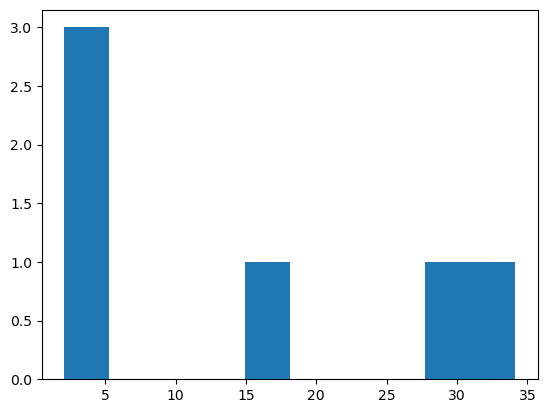

In [547]:
plt.hist(df_matches_particle.query('distance>1')['distance'])

In [559]:
df_matches_particle = df_matches_particle.query('distance<1').loc[:,['id', 'size', 'area', 'perimeter', 'circularity']]
df_matches_particle

,id,size,area,perimeter,circularity
0,Blank_-_01_0521_3,1.679639,2.260218,6.421024,0.688624
1,Blank_-_01_0521_4,1.452875,1.637440,5.087917,0.794559
2,Blank_-_01_0521_5,1.451943,1.654386,5.271980,0.747705
3,Blank_-_01_0521_7,1.171581,1.012544,4.030904,0.782798
4,Blank_-_01_0521_8,1.006954,0.838844,3.554955,0.833784
...,...,...,...,...,...
1230,MF_N_02_0409_101,1.402176,1.546353,5.310101,0.688881
1231,MF_N_02_0409_102,0.575783,0.243604,1.923420,0.827134
1232,MF_N_02_0409_103,1.052786,0.830371,3.739018,0.746101
1233,MF_N_02_0409_104,1.153481,1.054909,4.107146,0.785553


In [564]:
gloves_data_raman_res = gloves_data_raman_res.merge(df_matches_particle)
gloves_data_raman_res

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,id_top_match_slopp_stearates,data_source_slopp_stearates,polymer_rebecca_stearates,hqi_rebecca_stearates,id_top_match_rebecca_stearates,data_source_rebecca_stearates,size,area,perimeter,circularity
0,0.068679,0.074065,0.071034,0.065058,0.047093,0.033149,0.026839,0.011299,-0.010163,0.012040,...,Sodium Stearate_15,stearates,Sodium Stearate,0.404022,Sodium Stearate_15,stearates,1.836663,2.633419,6.703690,0.736140
1,0.639523,0.605787,0.593576,0.588226,0.605935,0.638924,0.700918,0.677862,0.600250,0.548362,...,Calcium Stearate_102,stearates,Calcium Stearate,0.468796,Calcium Stearate_102,stearates,0.651304,0.302916,2.497942,0.609815
2,2.712312,2.882443,2.986626,3.064666,3.013808,2.937730,2.813776,2.706437,2.609756,2.684483,...,Calcium Stearate_102,stearates,Calcium Stearate,0.502736,Calcium Stearate_102,stearates,1.388501,1.506106,5.563866,0.611143
3,0.132527,0.125327,0.127415,0.130922,0.126859,0.119735,0.106798,0.104577,0.109229,0.105809,...,Sodium Stearate_15,stearates,Sodium Stearate,0.425920,Sodium Stearate_15,stearates,1.632973,1.673451,6.535387,0.492165
4,1.606523,1.639777,1.717443,1.794196,1.747182,1.683180,1.586928,1.492610,1.399531,1.431163,...,Calcium Stearate_102,stearates,Calcium Stearate,0.546601,Calcium Stearate_102,stearates,0.636946,0.275378,2.199516,0.715016
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1224,0.114177,0.105439,0.110182,0.117332,0.117448,0.113142,0.100444,0.103548,0.116788,0.104578,...,Sodium Stearate_89,stearates,Sodium Stearate,0.980794,Sodium Stearate_89,stearates,1.422096,1.533643,4.995885,0.771863
1225,0.437370,0.444869,0.446204,0.443742,0.413838,0.398329,0.410147,0.409680,0.401332,0.377332,...,Calcium Stearate_102,stearates,Calcium Stearate,0.959347,Calcium Stearate_102,stearates,1.331205,1.357825,4.697458,0.772963
1226,0.848493,0.941898,0.958407,0.953525,0.901739,0.860630,0.839792,0.838897,0.850794,0.812097,...,Calcium Stearate_102,stearates,Calcium Stearate,0.742729,Calcium Stearate_102,stearates,0.694288,0.379174,2.628095,0.689600
1227,-0.041655,-0.056600,-0.058043,-0.056168,-0.051042,-0.052543,-0.066624,-0.070305,-0.067314,-0.065294,...,Zinc Stearate_63,stearates,Zinc Stearate,0.995632,Zinc Stearate_63,stearates,2.594529,5.022470,9.855076,0.649588


In [565]:
gloves_data_raman_res.to_csv('gloves_contamination/results_raman/matches_all_raman.csv')

In [307]:
gloves_data_subs_info = np.array([x.split('_')[:3] for x in gloves_data_raman_res.loc[:,'id']])
gloves_data_subs_info

array([['MF', 'L', '01'],
       ['MF', 'L', '01'],
       ['MF', 'L', '01'],
       ...,
       ['KC', 'N', '02'],
       ['KC', 'N', '02'],
       ['KC', 'N', '02']], dtype='<U5')

In [308]:
gloves_data_subs_info = np.array([x.split('_')[:3] for x in gloves_data_raman_res.loc[:,'id']])
gloves_data_raman_res_ = gloves_data_raman_res.copy()
for lib in ['slopp', 'rebecca', 'stearates']:
    gloves_data_raman_res_['brand'] = gloves_data_subs_info[:, 0]
    gloves_data_raman_res_['material'] = gloves_data_subs_info[:, 1]
    gloves_data_raman_res_['substrate'] = gloves_data_subs_info[:, 2]
    gloves_data_raman_res_['hqi_filter'] = gloves_data_raman_res_['hqi_'+lib]
    gloves_data_raman_res_subs = (gloves_data_raman_res_.
     query('hqi_filter>=.7').
     iloc[:,-25:].
     groupby(['brand', 'material', 'substrate', 'polymer_'+lib]).
     count().
     iloc[:,:1].
     reset_index().
     pivot(index=['brand', 'material', 'substrate'], columns='polymer_'+lib, values='id'))
    
    gloves_data_raman_res_subs_all = (gloves_data_raman_res_.
     iloc[:,-25:].
     groupby(['brand', 'material', 'substrate']).
     count().
     iloc[:,:1].
     reset_index().set_index(['brand', 'material', 'substrate']))
    
    gloves_data_raman_res_subs[np.isnan(gloves_data_raman_res_subs)] = 0
    #print(gloves_data_ir_res_subs)
    gloves_data_raman_res_subs.to_csv('gloves_contamination/results_raman/matches_by_substrate_raman_'+lib+'.csv')
    
    #prop_table = gloves_data_raman_res_subs / np.array(gloves_data_raman_res_subs.sum(1))[:,None]
    #prop_table = prop_table.reset_index().groupby(['brand', 'material']).sum()/2
    #prop_table = np.clip(prop_table.iloc[1:,:] - np.array(prop_table.iloc[:1,:]), 0, a_max=None)
    
    
    #prop_table = pd.DataFrame((gloves_data_raman_res_subs.sum(1) / gloves_data_raman_res_subs_all.loc[:,'id']))
    #prop_table = prop_table.groupby(['brand', 'material']).sum() / 2
    #prop_table.columns = ['proportion']
    #prop_table = np.clip(prop_table.iloc[1:,:] - np.array(prop_table.iloc[:1,:]), 0, a_max=None)
    
    prop_table = gloves_data_raman_res_subs.reset_index().groupby(['brand', 'material']).sum()/2
    prop_table = prop_table / np.array(prop_table.sum(1))[:,None]
    
    prop_table.to_csv('gloves_contamination/results_raman/prop_matches_by_identities_raman_'+lib+'.csv')
     
    prop_table = pd.DataFrame((gloves_data_raman_res_subs.sum(1) / gloves_data_raman_res_subs_all.loc[:,'id']))
    prop_table = prop_table.groupby(['brand', 'material']).sum() / 2
    prop_table.columns = ['proportion']
    #prop_table = np.clip(prop_table.iloc[1:,:] - np.array(prop_table.iloc[:1,:]), 0, a_max=None)

    prop_table_both_subs = pd.DataFrame((gloves_data_raman_res_subs.sum(1) / gloves_data_raman_res_subs_all.loc[:,'id'])).reset_index().set_index(['brand', 'material']) 
    prop_table_both_subs.columns= ['substrate', 'proportion']
    prop_table_both_subs.iloc[np.where(np.isnan(prop_table_both_subs['proportion']))[0], :] = 0
    prop_table_both_subs['proportion'] = (prop_table_both_subs.iloc[:,1:] - prop_table) ** 2
    prop_table_std = np.sqrt(prop_table_both_subs.reset_index().groupby(['brand', 'material']).sum() / 2)
    prop_table = pd.concat([prop_table, prop_table_std], axis=1)
    prop_table.columns = ['mean', 'std']
    
    prop_table.to_csv('gloves_contamination/results_raman/prop_matches_raman_'+lib+'.csv')
    
    count_table_both_subs = pd.DataFrame(gloves_data_raman_res_subs.sum(1))
    count_table_both_subs.columns = ['x']
    count_table_both_subs = count_table_both_subs / Substrate_Area
    count_table_both_subs.iloc[np.where(np.isnan(count_table_both_subs))[0], :] = 0
    count_table = count_table_both_subs.reset_index().groupby(['brand', 'material']).sum() / 2
    count_table_std = np.sqrt(((count_table_both_subs - count_table) ** 2).reset_index().groupby(['brand', 'material']).sum() / 2 )

    count_table = pd.concat([count_table, count_table_std], axis=1)
    count_table.columns = ['mean', 'std']
    blank_corr = np.array(count_table.iloc[:1,:])
    blank_corr[0,1] = -blank_corr[0,1]

    count_table = count_table.iloc[1:,:] - blank_corr
    count_table.to_csv('gloves_contamination/results_raman/count_area_matches_raman_'+lib+'.csv')
#gloves_data_ir_res_subs

In [311]:
count_table

mean         std
brand material                         
CR    N            0.000000    0.000000
FB    L         7605.834538  966.965681
      N         2628.593056  438.275709
KC    L         2888.870108  531.590586
      N         1316.949529  739.656585
MF    L            0.000000    0.000000
      N          903.681841  281.287886

In [44]:
#idx_match = pred_slopp_stearates_df[0]['hqi_ref'] > .7#[True] * pred_flopp_df[0].shape[0]
#idx_match = np.logical_and(pred_slopp_df[0]['hqi_ref'] > .7, 
#                           pred_stearates_df[0]['hqi_ref'] > .7)
idx_match = pred_slopp_df[0]['hqi_ref']>=.7

#labels_slopp_stearates = np.unique(np.array(pred_slopp_stearates_df[0]['polymer_ref']))
labels_slopp_stearates = np.concatenate([np.array(list(set(pred_slopp_df[0]['polymer_ref']))),
                                         np.array(list(set(pred_stearates_df[0]['polymer_ref'])))])

labels_slopp_stearates = np.array(pd.DataFrame({'label':labels_slopp_stearates,
 'a':[1*('Stearate' in x) for x in labels_slopp_stearates]}).sort_values(['a', 'label'])['label'])

#labels_flopp = np.unique(np.array(pred_flopp_df[0]['polymer_ref']))
mat = confusion_matrix(np.array(pred_slopp_df[0]['polymer_ref'].loc[idx_match]), 
                       np.array(pred_slopp_stearates_df[0]['polymer_ref'].loc[idx_match]),
                       labels=labels_slopp_stearates)

mat2 = mat[mat.sum(1)>0,:]
idx_pos_col = mat2.sum(0)>0
mat2 = mat2[:, idx_pos_col]
mat2_count = mat2.copy()
mat2 = (mat2 / mat2.sum(1)[:,None])
mat2 = np.round(mat2, 2)

mat2_df = pd.DataFrame(mat2)
mat2_df.columns = labels_slopp_stearates[idx_pos_col]
mat2_df['index'] = labels_slopp_stearates[mat.sum(1)>0]
mat2_df = mat2_df.set_index('index')
mat2_df.to_csv('gloves_contamination/results_raman/confusion_matrix_slopp_stearates.csv')
mat2_df

,Polyamide,Polyethylene,Calcium Stearate,Magnesium Stearate v2,Sodium Stearate,Zinc Stearate
index,,,,,,
Polyamide,0.25,0.00,0.25,0.50,0.00,0.00
Polyethylene,0.00,0.02,0.67,0.05,0.12,0.14
Polyethylene-co-Polypropylene,0.00,0.00,0.70,0.20,0.00,0.10
Polypropylene,0.00,0.00,0.86,0.07,0.07,0.00


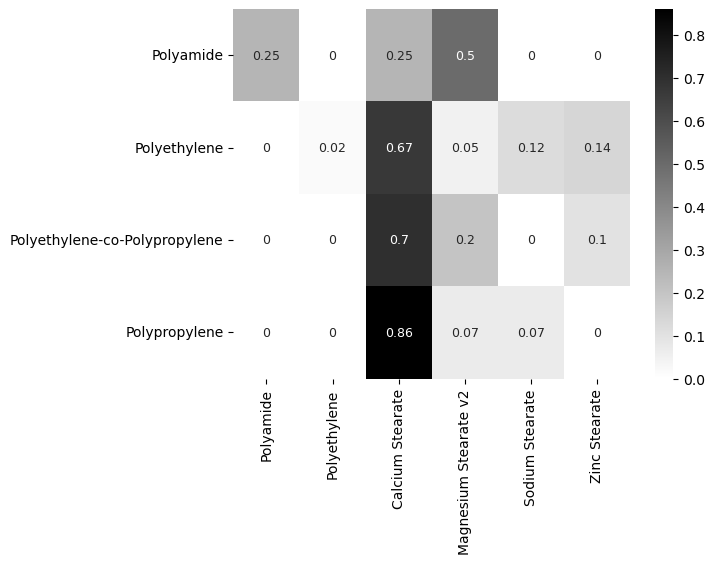

In [45]:
_ = sns.heatmap(mat2, 
                #annot=True,
                yticklabels=labels_slopp_stearates[mat.sum(1)>0], 
                xticklabels=labels_slopp_stearates[idx_pos_col],#[mat.sum(0)>0],
                cmap = 'binary',
                annot=True,
                annot_kws={'fontsize':9})
_ = plt.savefig('gloves_contamination/results_raman/confusion_matrix_slopp_stearates.png',bbox_inches='tight')

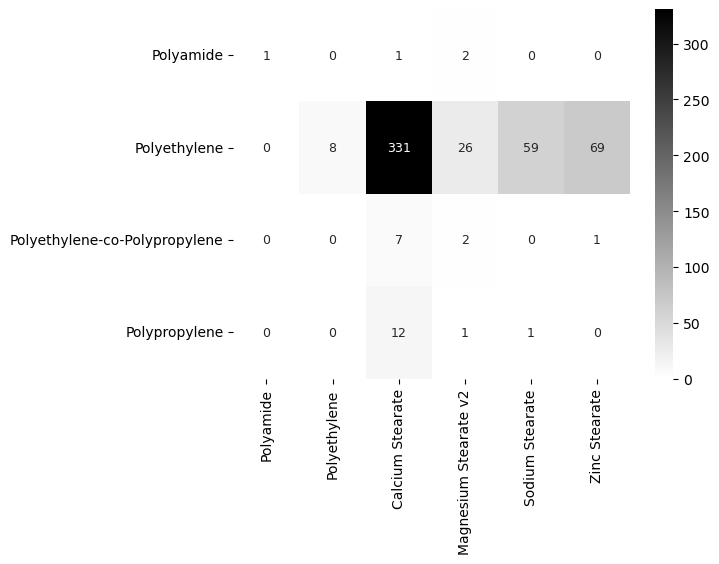

In [46]:
_ = sns.heatmap(mat2_count, 
                #annot=True,
                yticklabels=labels_slopp_stearates[mat.sum(1)>0], 
                xticklabels=labels_slopp_stearates[idx_pos_col],#[mat.sum(0)>0],
                cmap = 'binary',
                annot=True,
                annot_kws={'fontsize':9},
                fmt=".0f")
_ = plt.savefig('gloves_contamination/results_raman/confusion_matrix_slopp_stearates_count.png',bbox_inches='tight')

In [47]:
#idx_match = pred_rebecca_stearates_df[0]['hqi_ref'] > .7#[True] * pred_flopp_df[0].shape[0]
#idx_match = np.logical_and(pred_rebecca_df[0]['hqi_ref'] > .7, 
#                           pred_stearates_df[0]['hqi_ref'] > .7)
idx_match = pred_rebecca_df[0]['hqi_ref']>=.7#[True] * pred_flopp_df[0].shape[0]

#labels_rebecca_stearates = np.unique(np.array(pred_rebecca_stearates_df[0]['polymer_ref']))
labels_rebecca_stearates = np.concatenate([np.array(list(set(pred_rebecca_df[0]['polymer_ref']))),
                                           np.array(list(set(pred_stearates_df[0]['polymer_ref'])))])

labels_rebecca_stearates = np.array(pd.DataFrame({'label':labels_rebecca_stearates,
 'a':[1*('Stearate' in x) for x in labels_rebecca_stearates]}).sort_values(['a', 'label'])['label'])

#labels_flopp = np.unique(np.array(pred_flopp_df[0]['polymer_ref']))
mat = confusion_matrix(np.array(pred_rebecca_df[0]['polymer_ref'].loc[idx_match]), 
                       np.array(pred_rebecca_stearates_df[0]['polymer_ref'].loc[idx_match]),
                       labels=labels_rebecca_stearates)

mat2 = mat[mat.sum(1)>0,:]
idx_pos_col = mat2.sum(0)>0
mat2 = mat2[:, idx_pos_col]
mat2_count = mat2.copy()
mat2 = (mat2 / mat2.sum(1)[:,None])
mat2 = np.round(mat2, 2)

mat2_df = pd.DataFrame(mat2)
mat2_df.columns = labels_rebecca_stearates[idx_pos_col]
mat2_df['index'] = labels_rebecca_stearates[mat.sum(1)>0]
mat2_df = mat2_df.set_index('index')
mat2_df.to_csv('gloves_contamination/results_raman/confusion_matrix_rebecca_raman_stearates.csv')
mat2_df

,PE,PP,Calcium Stearate,Magnesium Stearate v2,Sodium Stearate,Zinc Stearate
index,,,,,,
PE,0.01,0.00,0.72,0.05,0.1,0.11
PP,0.00,0.29,0.50,0.00,0.0,0.21


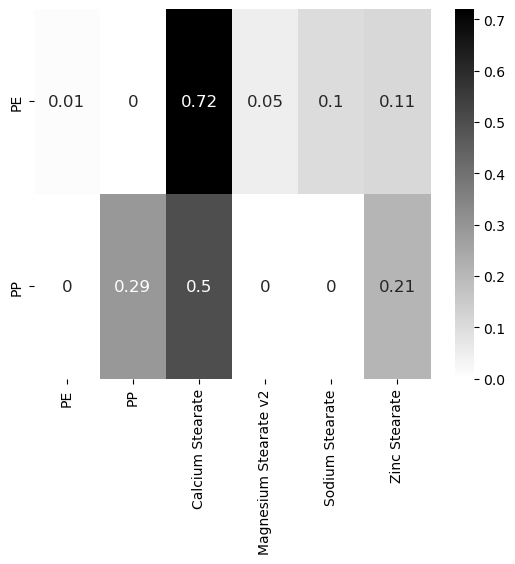

In [48]:
_ = sns.heatmap(mat2, 
                #annot=True,
                yticklabels=labels_rebecca_stearates[mat.sum(1)>0], 
                xticklabels=labels_rebecca_stearates[idx_pos_col],
                cmap = 'binary',
                annot=True,
                annot_kws={'fontsize':12})
_ = plt.savefig('gloves_contamination/results_raman/confusion_matrix_rebecca_raman_stearates.png',bbox_inches='tight')

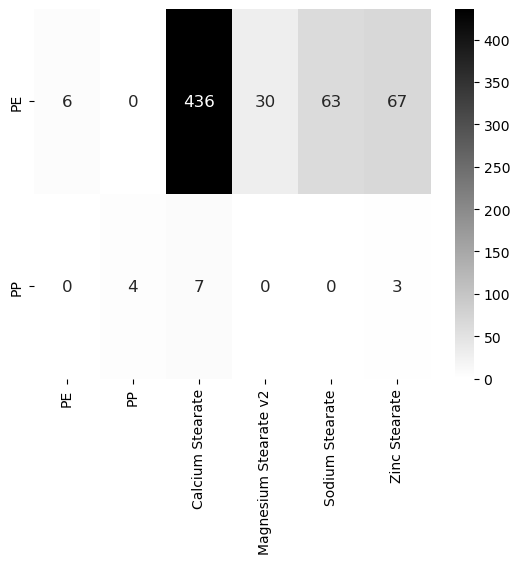

In [49]:
_ = sns.heatmap(mat2_count, 
                #annot=True,
                yticklabels=labels_rebecca_stearates[mat.sum(1)>0], 
                xticklabels=labels_rebecca_stearates[idx_pos_col],
                cmap = 'binary',
                annot=True,
                annot_kws={'fontsize':12},
                fmt=".0f")
_ = plt.savefig('gloves_contamination/results_raman/confusion_matrix_rebecca_raman_stearates_count.png',bbox_inches='tight')

In [50]:
gloves_data_ir = pd.read_csv('gloves_contamination/gloves_data_ir_final.csv')
del gloves_data_ir['Unnamed: 0']
gloves_data_ir.columns = list(np.float64(gloves_data_ir.columns[:-4])) + list(gloves_data_ir.columns[-4:])

gloves_data_ir_sat = gloves_data_ir.iloc[:,-2:]
gloves_data_subs_info = np.array([x.split('_')[:3] for x in gloves_data_ir.loc[:,'id']])

gloves_data_ir_sat['brand'] = gloves_data_subs_info[:, 0]
gloves_data_ir_sat['material'] = gloves_data_subs_info[:, 1]
gloves_data_ir_sat['substrate'] = gloves_data_subs_info[:, 2]
gloves_data_ir_sat.to_csv('gloves_contamination/results/split_ir_background.csv')

In [51]:
gloves_data_raman = pd.read_csv('gloves_contamination/gloves_data_raman_final.csv')
del gloves_data_raman['Unnamed: 0']
gloves_data_raman.columns = list(np.float64(gloves_data_raman.columns[:-3])) + list(gloves_data_raman.columns[-3:])
gloves_data_raman['saturated'] = ["saturated" if x in ids_sat else "not saturated" for x in gloves_data_raman['id']]
gloves_data_raman_sat = gloves_data_raman.iloc[:,-2:]
gloves_data_subs_info = np.array([x.split('_')[:3] for x in gloves_data_raman.loc[:,'id']])

gloves_data_raman_sat['brand'] = gloves_data_subs_info[:, 0]
gloves_data_raman_sat['material'] = gloves_data_subs_info[:, 1]
gloves_data_raman_sat['substrate'] = gloves_data_subs_info[:, 2]
gloves_data_raman_sat.to_csv('gloves_contamination/results_raman/split_raman_saturation.csv')


In [52]:
all_ref_df = pd.concat([slopp_df,rebecca_df,stearates_df], axis=0).reset_index(drop=True)
all_ref_df['data_source'] = (['flopp']*slopp_df.shape[0] + 
                             ['rebecca']*rebecca_df.shape[0] +
                             ['stearates']*stearates_df.shape[0])
all_ref_df.to_csv('gloves_contamination/all_ref_data_raman_final.csv')

In [53]:
#ids_sat = list(saturated_wn_dict.keys())
#len(ids_sat)

In [54]:
#pd.DataFrame({'ref':['slopp','rebecca','stearates'],
    #'no baseline correct (355)':[392,1014,706],
#    'with specy (355)':         [525,816,657],
    #'no baseline correct (530)':[395,1063,706],
#    'with specy (530)':         [539,860,667],
#              })